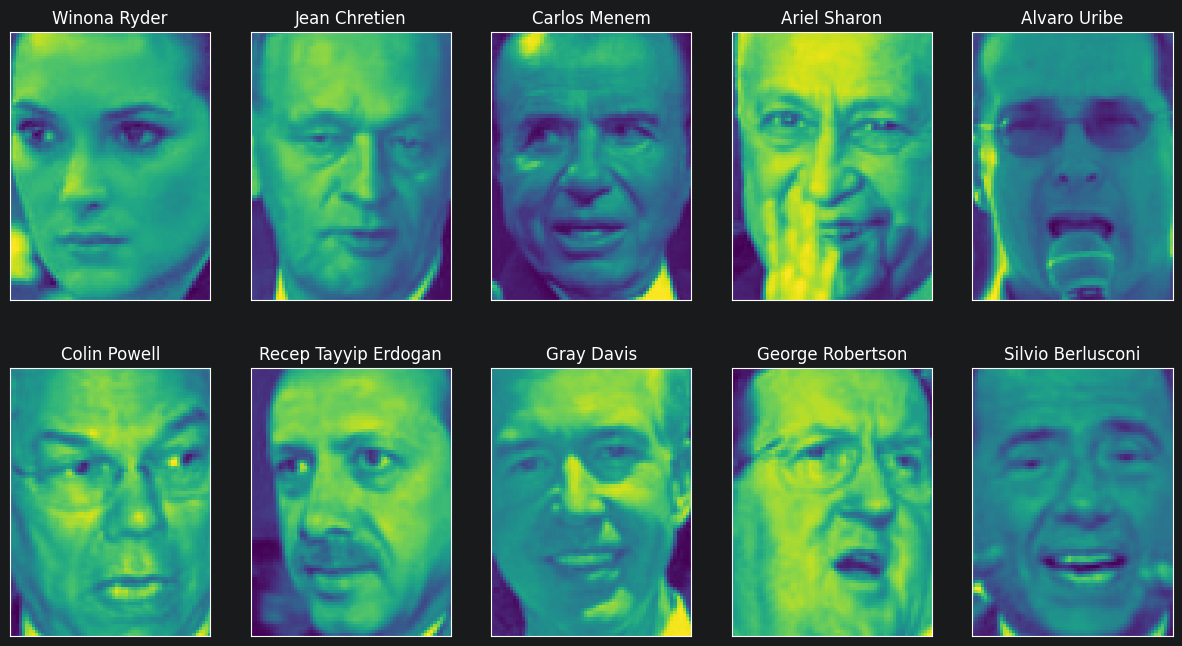

In [58]:
import matplotlib.pyplot as plt
import mglearn
import numpy as np
from sklearn.datasets import fetch_lfw_people
import pandas as pd


people = fetch_lfw_people(min_faces_per_person = 20, resize = 0.7)
image_shape = people.images[0].shape

fig , axes = plt.subplots(2, 5, figsize=(15,8),
                          subplot_kw={'xticks':(), 'yticks':()})

for target , images, ax in zip(people.target , people.images , axes.ravel()):
    ax.imshow(images)
    ax.set_title(people.target_names[target])


In [59]:
print(f"people.images.shape = {people.images.shape}")
print(f"number of classes = {len(people.target_names)}")

people.images.shape = (3023, 87, 65)
number of classes = 62


In [60]:
from sklearn.model_selection import train_test_split
mask = np.zeros(people.target.shape, dtype = np.bool)
for target in np.unique(people.target):
    mask[np.where(people.target == target)[0][:50]] = 1

X_people = people.data[mask]
y_people = people.target[mask]

X_people = X_people / 255

X_train, X_test, y_train, y_test = train_test_split(X_people, y_people, stratify = y_people, random_state = 0)


In [61]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier()

knn.fit(X_train, y_train)

print(f"knn.score = {knn.score(X_test, y_test):.2f}")


knn.score = 0.21


In [62]:
from sklearn.decomposition import PCA
pca = PCA(n_components = 100, whiten =  True, random_state = 0 ).fit(X_train)
X_train_pca = pca.transform(X_train)
X_test_pca = pca.transform(X_test)

print("X_train_pca.shape = ", X_train_pca.shape)

X_train_pca.shape =  (1547, 100)


In [63]:
knn2 = KNeighborsClassifier(n_neighbors = 1)
knn2.fit(X_train_pca, y_train)

print(f"Test set accuracy with pca preprocessing= {knn2.score(X_test_pca, y_test):.2f}")

Test set accuracy with pca preprocessing= 0.30


In [64]:
print(f"pca.components_.shape = {pca.components_.shape}")

pca.components_.shape = (100, 5655)


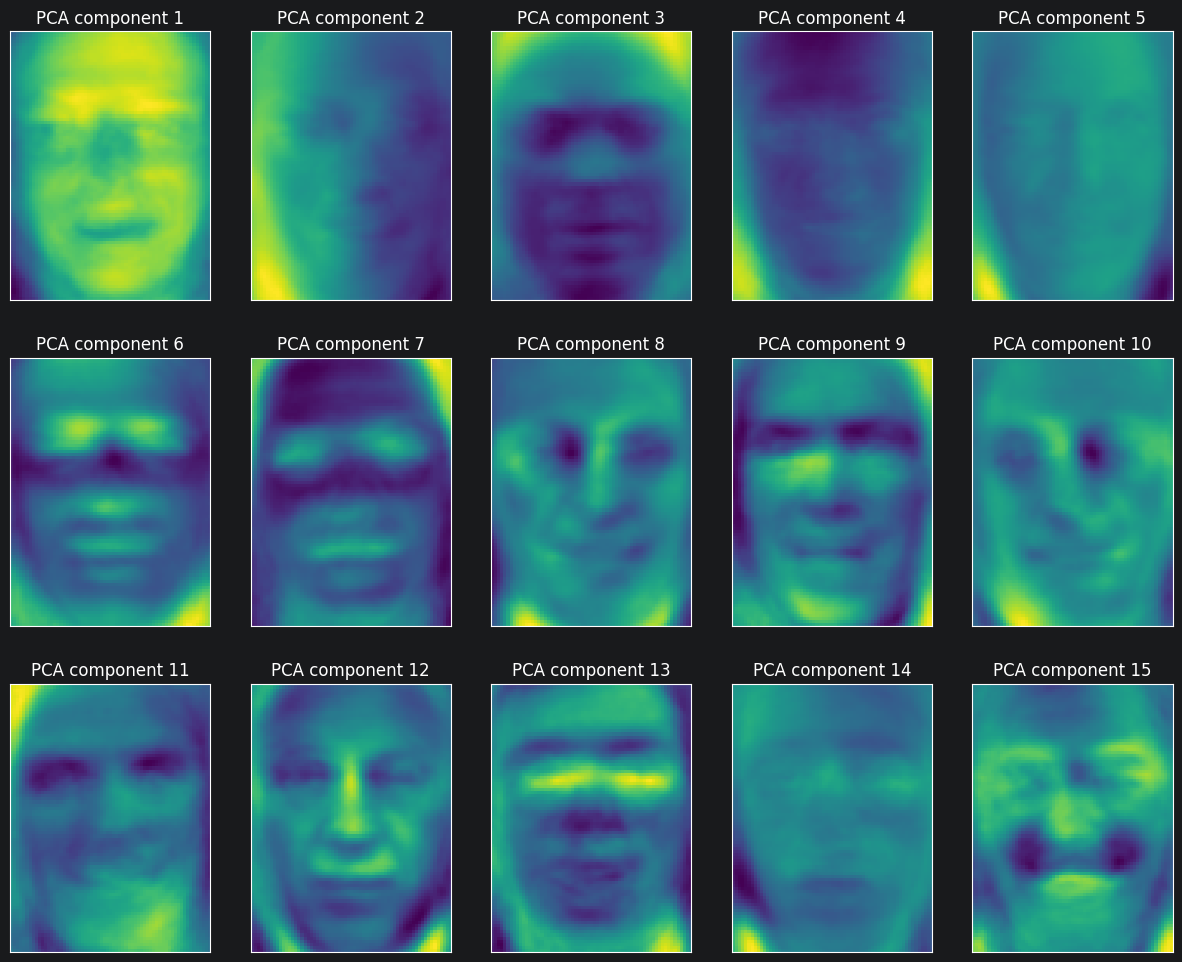

In [65]:
fix, axes = plt.subplots(3 , 5, figsize = (15, 12),
                         subplot_kw={'xticks':(), 'yticks':()})
for i, (component , ax) in enumerate(zip(pca.components_, axes.ravel())):
    ax.imshow(component.reshape(image_shape),
              cmap = 'viridis',)
    ax.set_title(f"PCA component {i+1}")


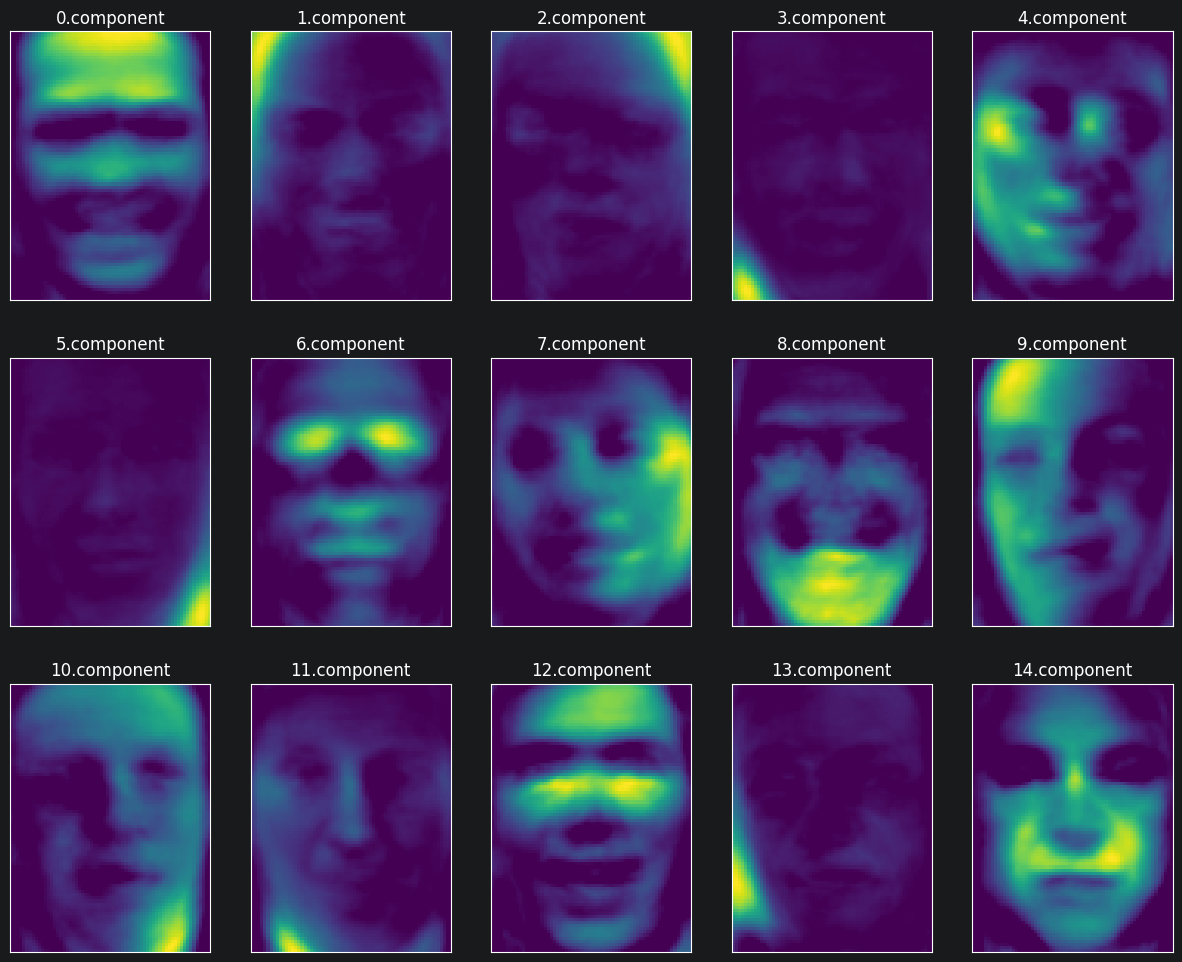

In [57]:
from sklearn.decomposition import NMF
nmf = NMF(n_components = 15, random_state = 0, max_iter = 5000)
nmf.fit(X_train)
X_train_nmf = nmf.transform(X_train)
X_test_nmf = nmf.transform(X_test)

fix, axes = plt.subplots(3, 5, figsize = (15, 12),
                         subplot_kw={'xticks':(), 'yticks':()})
for i, (component , ax) in enumerate(zip(nmf.components_, axes.ravel())):
    ax.imshow(component.reshape(image_shape))
    ax.set_title(f"{i}.component")

In [18]:
from sklearn.datasets import load_digits
digits = load_digits()

print(f"keys: {digits.keys()}")
print(f"-------->>> Number of images and their shapes: {digits.images.shape}")
print(digits.DESCR)

keys: dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])
-------->>> Number of images and their shapes: (1797, 8, 8)
.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and differen

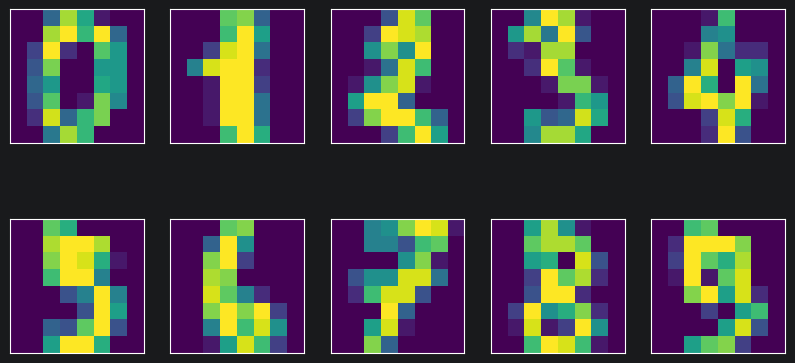

In [19]:
fig, axes = plt.subplots(2, 5, figsize = (10, 5),
                        subplot_kw = {'xticks':(), 'yticks':()})
for ax, img in zip(axes.ravel(), digits.images):
    ax.imshow(img)